In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df = pd.read_csv('/content/diabetes.csv')

In [50]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [51]:
print(df.shape)

(768, 9)


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [53]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [54]:
print(df['Outcome'].value_counts)

<bound method IndexOpsMixin.value_counts of 0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64>


In [55]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


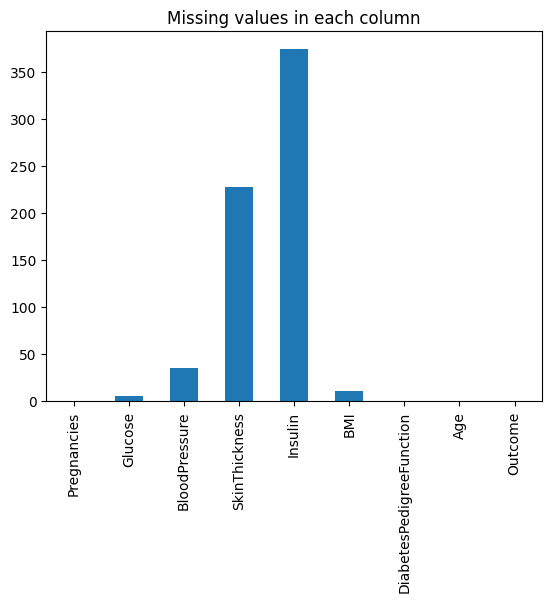

In [56]:
# missing values graph
df.isnull().sum().plot(kind='bar')
plt.title("Missing values in each column")
plt.show()

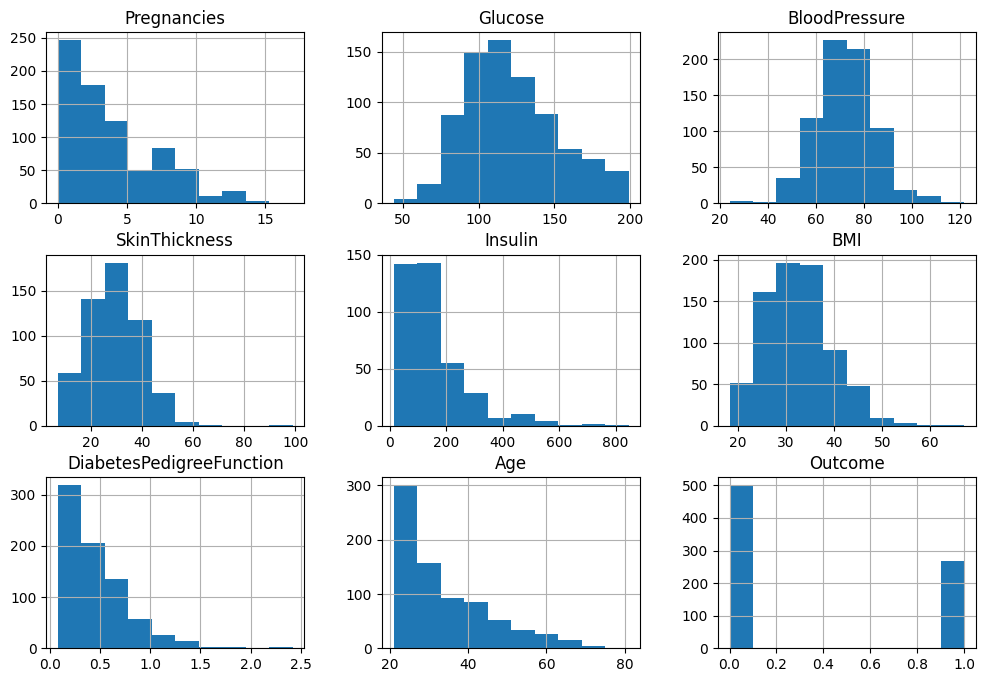

In [57]:
# histogram of all columns
df.hist(figsize=(12, 8))
plt.show()

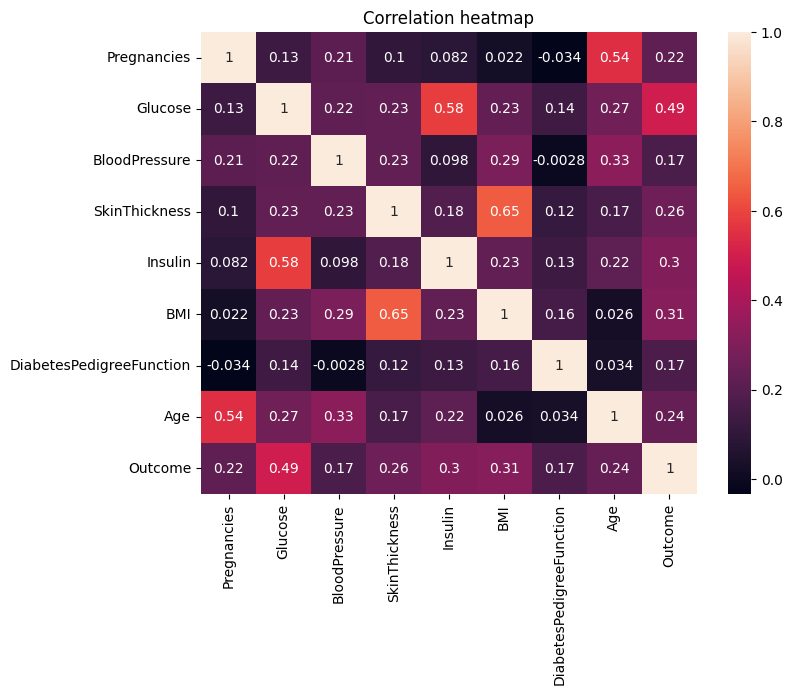

In [58]:
# correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation heatmap")
plt.show()

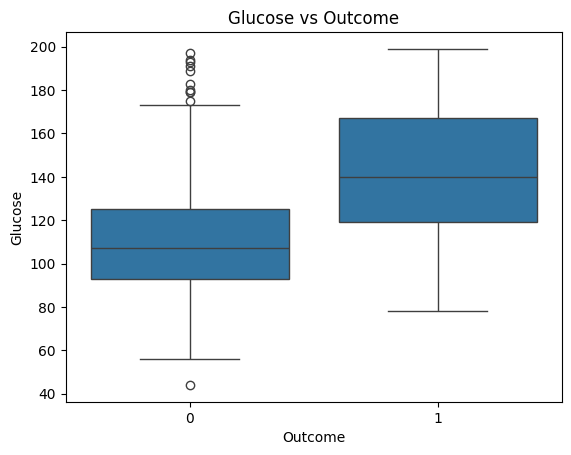

In [59]:
# glucose for diabetes and non diabetes
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title("Glucose vs Outcome")
plt.show()


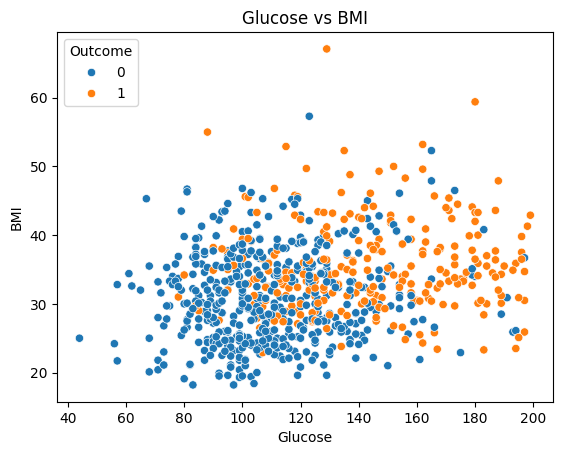

In [60]:
# glucose vs BMI
sns.scatterplot(x='Glucose', y='BMI', hue='Outcome', data=df)
plt.title("Glucose vs BMI")
plt.show()

In [61]:
from sklearn.model_selection import train_test_split


In [62]:
X = df.drop('Outcome', axis=1)   # input features
y = df['Outcome']   #target

In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [64]:
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


In [65]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)
print(np.isnan(X_train_imp).sum(), np.isnan(X_test_imp).sum())

0 0


In [66]:
# pipeline: fill missing -> scale -> logistic regression
log_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))
])

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, roc_curve

In [68]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)


In [69]:
print("Precision:", round(prec, 3))

Precision: 0.603


In [70]:
print("Accuracy :", round(acc, 3))

Accuracy : 0.734


In [71]:
print("Recall   :", round(rec, 3))

Recall   : 0.704


In [72]:
print("F1 score :", round(f1, 3))

F1 score : 0.65


In [73]:
print("ROC-AUC  :", round(auc, 3))

ROC-AUC  : 0.813


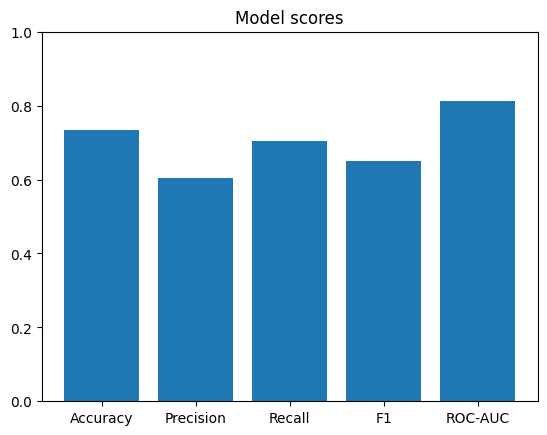

In [74]:
# model scores in one graph
names = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
scores = [acc, prec, rec, f1, auc]
plt.bar(names, scores)
plt.ylim(0, 1)
plt.title("Model scores")
plt.show()

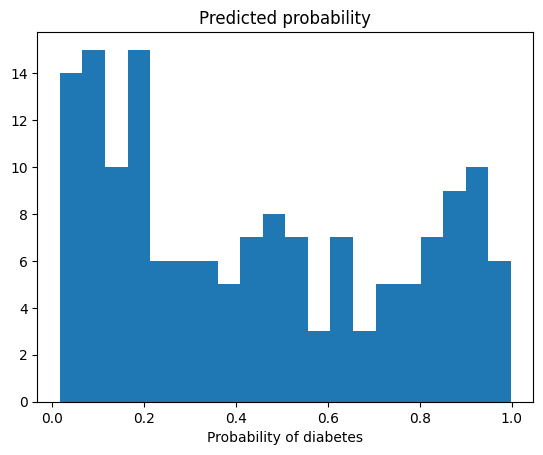

In [75]:
# predicted probability graph
plt.hist(y_prob, bins=20)
plt.xlabel("Probability of diabetes")
plt.title("Predicted probability")
plt.show()

In [76]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[75 25]
 [16 38]]


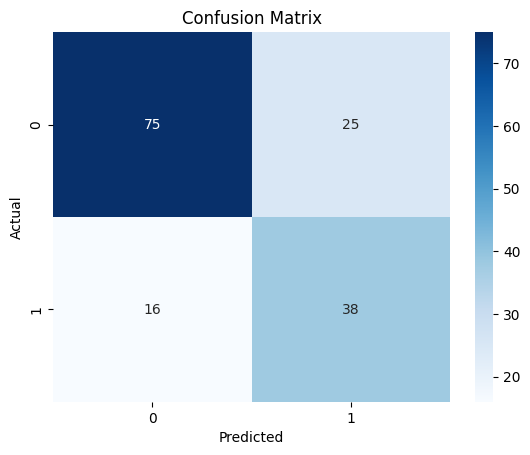

In [77]:
# confusion matrix plot
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()



Text(0.5, 1.0, 'ROC Curve')

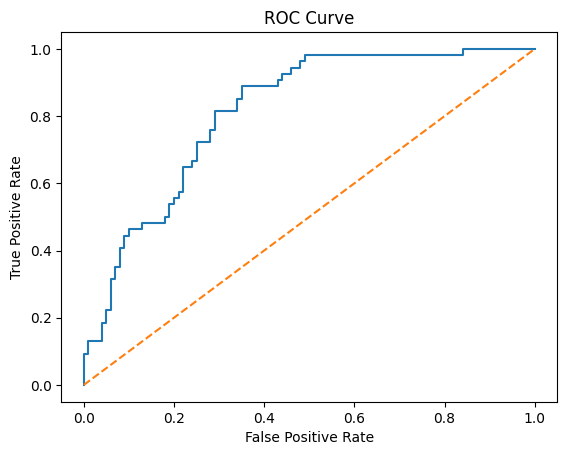

In [78]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
